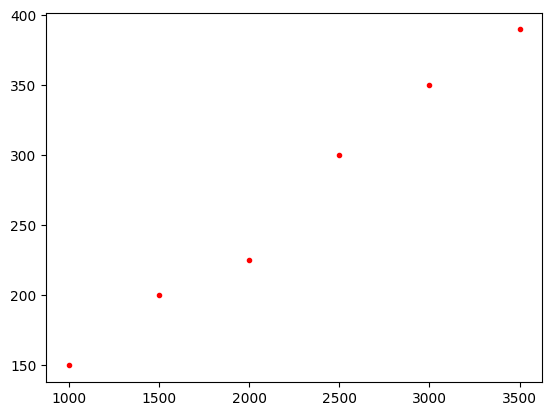

In [1]:
import numpy as np
import matplotlib.pyplot as plt

house_size = [1000, 1500, 2000, 2500, 3000, 3500]
house_price = [150, 200, 225, 300, 350, 390]

plt.scatter(house_size, house_price, marker = '.', color = 'red')
plt.show()

Now to get best line we will use least square problem's funtion:

f(w0, w1) = 1/2m summation of all (Yi - (w0 + w1xi))^2

In [2]:
house_size = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5]  # in thousands of sq ft (x)
house_price = [150, 200, 225, 300, 350, 390] # y

x = house_size
y = house_price
m = len(house_price) #our "M" that will help us to avg 
k=0
max_iter=1000
tol=1e-6
alpha = 0.1

#current position
w = [0.0,0.0] #w0, w1 (remember we do x*w1) w0 is bias 

while max_iter > k:

    #new position = current_pos + (alpha * direction)

    #so we need direction right now for that we need gradient for that we need summation of the middel part:
    summation_of_errors_for_w0 = 0
    summation_of_errors_for_w1 = 0
    for i in range(m):
        current_error = y[i] - (w[0] + w[1] * x[i])
        summation_of_errors_for_w0 = summation_of_errors_for_w0 + current_error

        #this is bcz for w1 slope we need to multiple another x[i] at the end of the error
        summation_of_errors_for_w1 = summation_of_errors_for_w1 + (current_error * x[i])

    #now to get the gradient of w0:
    grad_w0 = -(1/m * summation_of_errors_for_w0)

    #now for the gradient of w1:

    grad_w1 = -1/m * summation_of_errors_for_w1

    grads = np.array([grad_w0, grad_w1])

    direction = -grads

    #newpositon:
    new_pos = w + (alpha * direction)

    w = new_pos

    #update:
    k = k + 1

print(f'Current bias and slopes: {w}')


Current bias and slopes: [47.38082831 98.5714777 ]


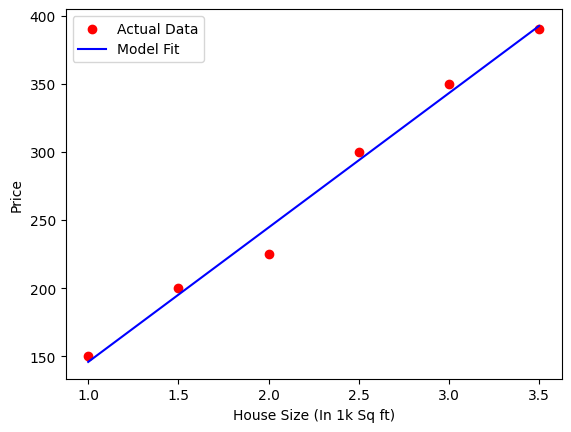

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Generate x values for a smooth line from min to max house size
x_line = np.linspace(min(house_size), max(house_size), 100)

# 2. Calculate corresponding y values using y_hat = w0 + w1 * x
y_line = w[0] + w[1] * x_line

# 3. Plot both the scatter data and the regression line
plt.scatter(house_size, house_price, color='red', label='Actual Data')
plt.plot(x_line, y_line, color='blue', label='Model Fit')

plt.xlabel('House Size (In 1k Sq ft)')
plt.ylabel('Price')
plt.legend()
plt.show()